# Employee Attrition: Exploratory Data Analysis

**Business problem:** Losing skilled employees is expensive (recruitment costs, onboarding time, lost institutional knowledge, and disrupted team velocity). If we can understand *who* is likely to leave and *why*, HR and leadership can proactively intervene before they resign.

**Objective of this notebook:**
- Inspect the dataset structure, types, and summary statistics.
- Audit data quality (missing values, duplicates, constant/zero-variance columns, and outliers).
- Explore univariate distributions and bivariate relationships with `Attrition`.
- Summarize actionable **Key Insights & Recommendations** for both HR retention and feature engineering.

## 1. Imports & settings

In [17]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/HR-Employee-Attrition.csv"

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100

from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGURES_DIR = ROOT / 'reports' / 'figures'

## 2. Load the data

In [18]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 1,470 | Columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


### 2.1 Target definition & schema inspection

In [19]:
TARGET = "Attrition" 

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### 2.2 Descriptive statistics

In [21]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Age,"1,470.00",36.92,9.14,18.00,30.00,36.00,43.00,60.00
DailyRate,"1,470.00",802.49,403.51,102.00,465.00,802.00,"1,157.00","1,499.00"
DistanceFromHome,"1,470.00",9.19,8.11,1.00,2.00,7.00,14.00,29.00
Education,"1,470.00",2.91,1.02,1.00,2.00,3.00,4.00,5.00
EmployeeCount,"1,470.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00
EmployeeNumber,"1,470.00","1,024.87",602.02,1.00,491.25,"1,020.50","1,555.75","2,068.00"
EnvironmentSatisfaction,"1,470.00",2.72,1.09,1.00,2.00,3.00,4.00,4.00
HourlyRate,"1,470.00",65.89,20.33,30.00,48.00,66.00,83.75,100.00
JobInvolvement,"1,470.00",2.73,0.71,1.00,2.00,3.00,3.00,4.00
JobLevel,"1,470.00",2.06,1.11,1.00,1.00,2.00,3.00,5.00


## 3. Data quality

### 3.1 Missing values

In [22]:
missing = (
    df.isnull().sum().to_frame("missing_count").sort_values("missing_count", ascending=False)
)
missing[missing["missing_count"] > 0]

,missing_count


In [23]:
print(f"Total missing values across entire dataset: {df.isnull().sum().sum()}")

Total missing values across entire dataset: 0


### 3.2 Duplicate rows & redundant identifier columns

In [24]:
dup = df.duplicated().sum()
print(f"Duplicate rows: {dup:,} ({dup / len(df):.2%})")

Duplicate rows: 0 (0.00%)


In [25]:
redundant_cols = [c for c in df.columns if df[c].nunique() == 1 or c == "EmployeeNumber"]
for c in redundant_cols:
    print(f"Redundant / Non-informative column: {c} | Unique values: {df[c].unique()[:3]} (nunique={df[c].nunique()})")

Redundant / Non-informative column: EmployeeCount | Unique values: [1] (nunique=1)
Redundant / Non-informative column: EmployeeNumber | Unique values: [1 2 4] (nunique=1470)
Redundant / Non-informative column: Over18 | Unique values: ['Y'] (nunique=1)
Redundant / Non-informative column: StandardHours | Unique values: [80] (nunique=1)


### 3.3 Categorical consistency

In [26]:
cat_cols = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
for c in cat_cols:
    print(df[c].value_counts(dropna=False), "\n")

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64 

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64 

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64 

Gender
Male      882
Female    588
Name: count, dtype: int64 

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64 

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64 

OverTime
No     1054
Yes     416
Name: count, dtype: int64 



### 3.4 Outliers (IQR rule)

In [27]:
num_cols = [
    "Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
    "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
    "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
    "YearsSinceLastPromotion", "YearsWithCurrManager"
]

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "outliers": {c: iqr_outliers(df[c]) for c in num_cols},
}).assign(pct=lambda d: d["outliers"] / len(df) * 100).sort_values("outliers", ascending=False)

,outliers,pct
TrainingTimesLastYear,238,16.19
MonthlyIncome,114,7.76
YearsSinceLastPromotion,107,7.28
YearsAtCompany,104,7.07
TotalWorkingYears,63,4.29
NumCompaniesWorked,52,3.54
YearsInCurrentRole,21,1.43
YearsWithCurrManager,14,0.95
Age,0,0.00
DailyRate,0,0.00


> **Note:**
- **`TrainingTimesLastYear`** (238 outliers, **16.19%**): With $Q_1 = 2$ and $Q_3 = 3$ ($IQR = 1$), the 1.5×IQR boundaries are $[0.5, 4.5]$. Consequently, values 1, 2, 3, and 4 fall strictly within normal bounds, while values **0** ($n=54$), **5** ($n=119$), and **6** ($n=65$) fall outside ($54 + 119 + 65 = 238$). These reflect valid enterprise training schedules rather than data entry errors.
- **`MonthlyIncome`** (114 outliers, **7.76%**): Employees earning over ~$16,580 (up to $19,999) represent directors and senior executives rather than erroneous data.
- **Tenure Features (`YearsSinceLastPromotion`, `YearsAtCompany`, `TotalWorkingYears`):** Outliers reflect long-tenured veteran personnel (e.g. 10–15 years without promotion, up to 40 years of service).
- **Modeling implication:** Tree-based models (Random Forest, XGBoost) handle these distributions naturally; monotonic transformations can be applied if evaluating linear models.


## 4. The target: `Attrition`

Attrition
No     1233
Yes     237

Overall attrition rate: 16.1%


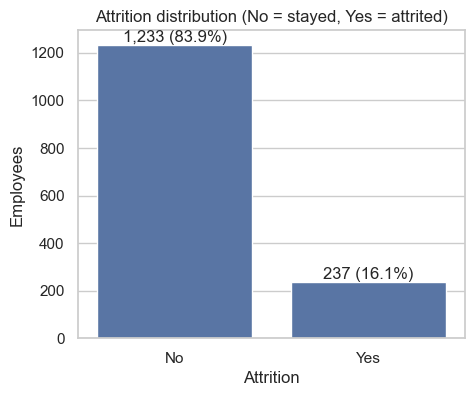

In [28]:
counts = df[TARGET].value_counts().sort_index()
rate = (df[TARGET] == "Yes").mean()
print(counts.to_string())
print(f"\nOverall attrition rate: {rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax)
ax.set(title="Attrition distribution (No = stayed, Yes = attrited)", xlabel="Attrition", ylabel="Employees")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,} ({v/len(df):.1%})", ha="center", va="bottom")
plt.savefig(FIGURES_DIR / '01_attrition_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Single-variable analysis (univariate)

### 5.1 Numeric columns

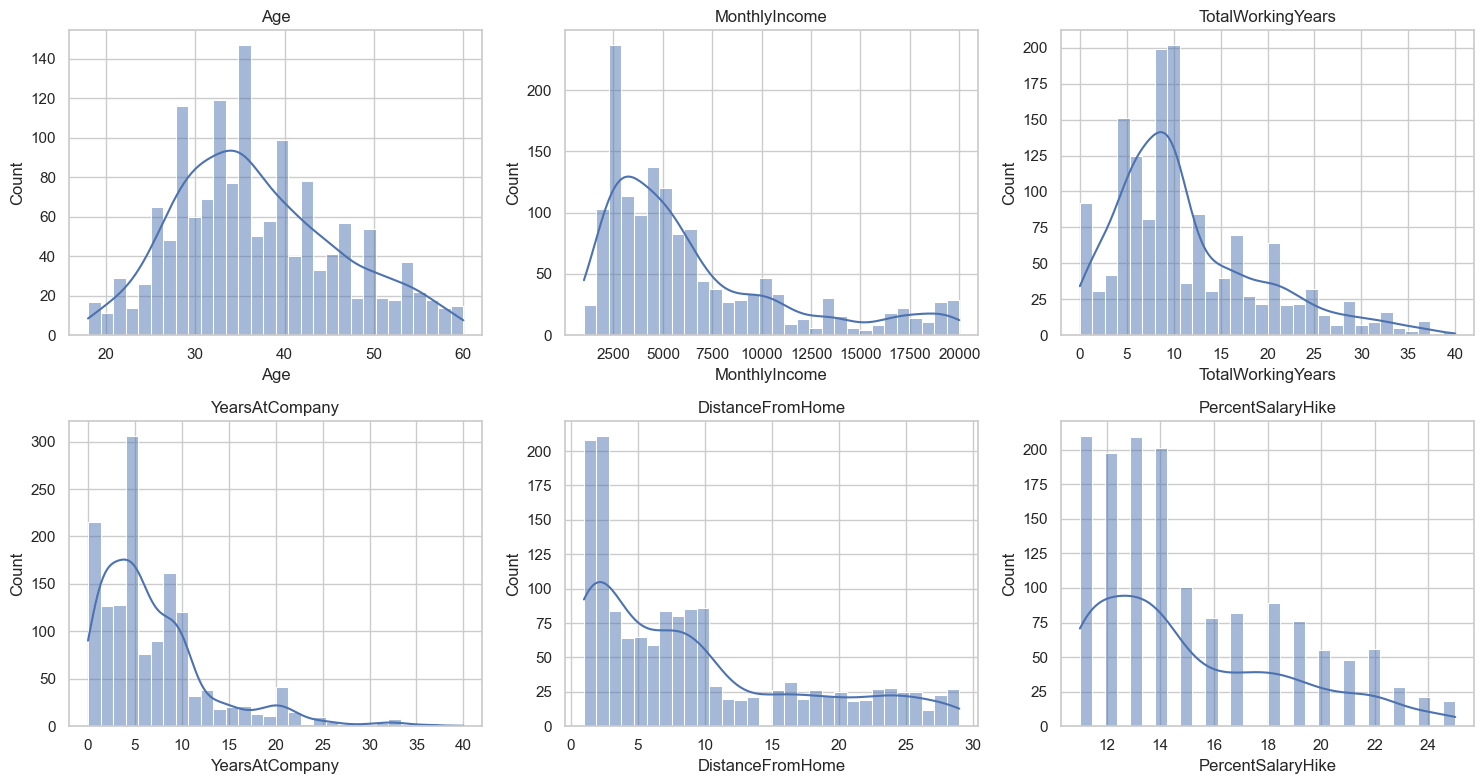

In [29]:
key_num_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "DistanceFromHome", "PercentSalaryHike"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), key_num_cols):
    sns.histplot(df[c], bins=30, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_numeric_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

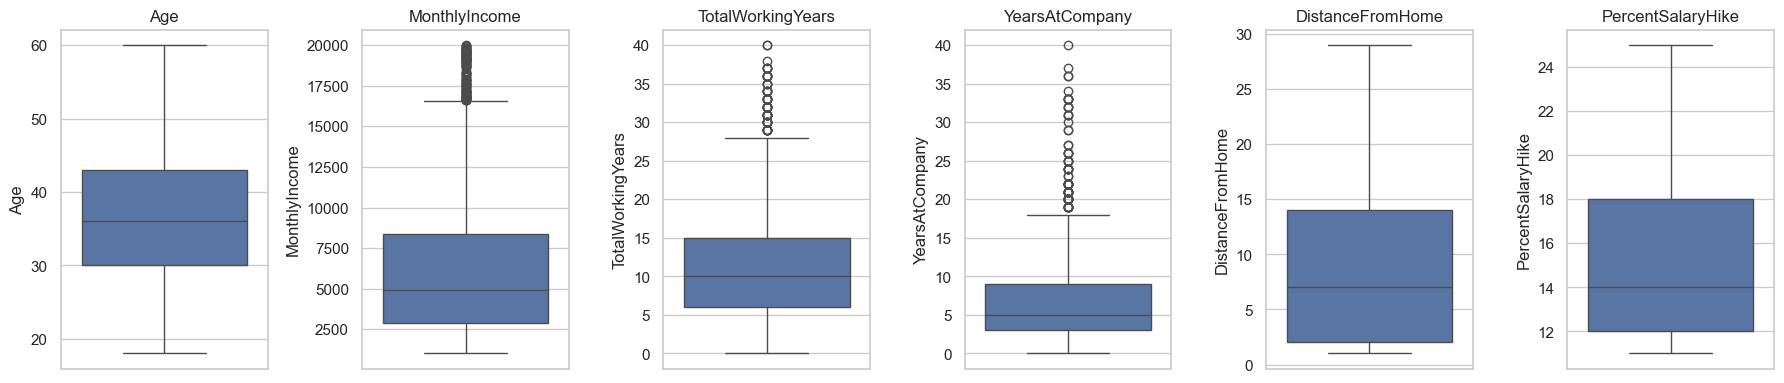

In [30]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for ax, c in zip(axes, key_num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_numeric_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Discrete and categorical columns

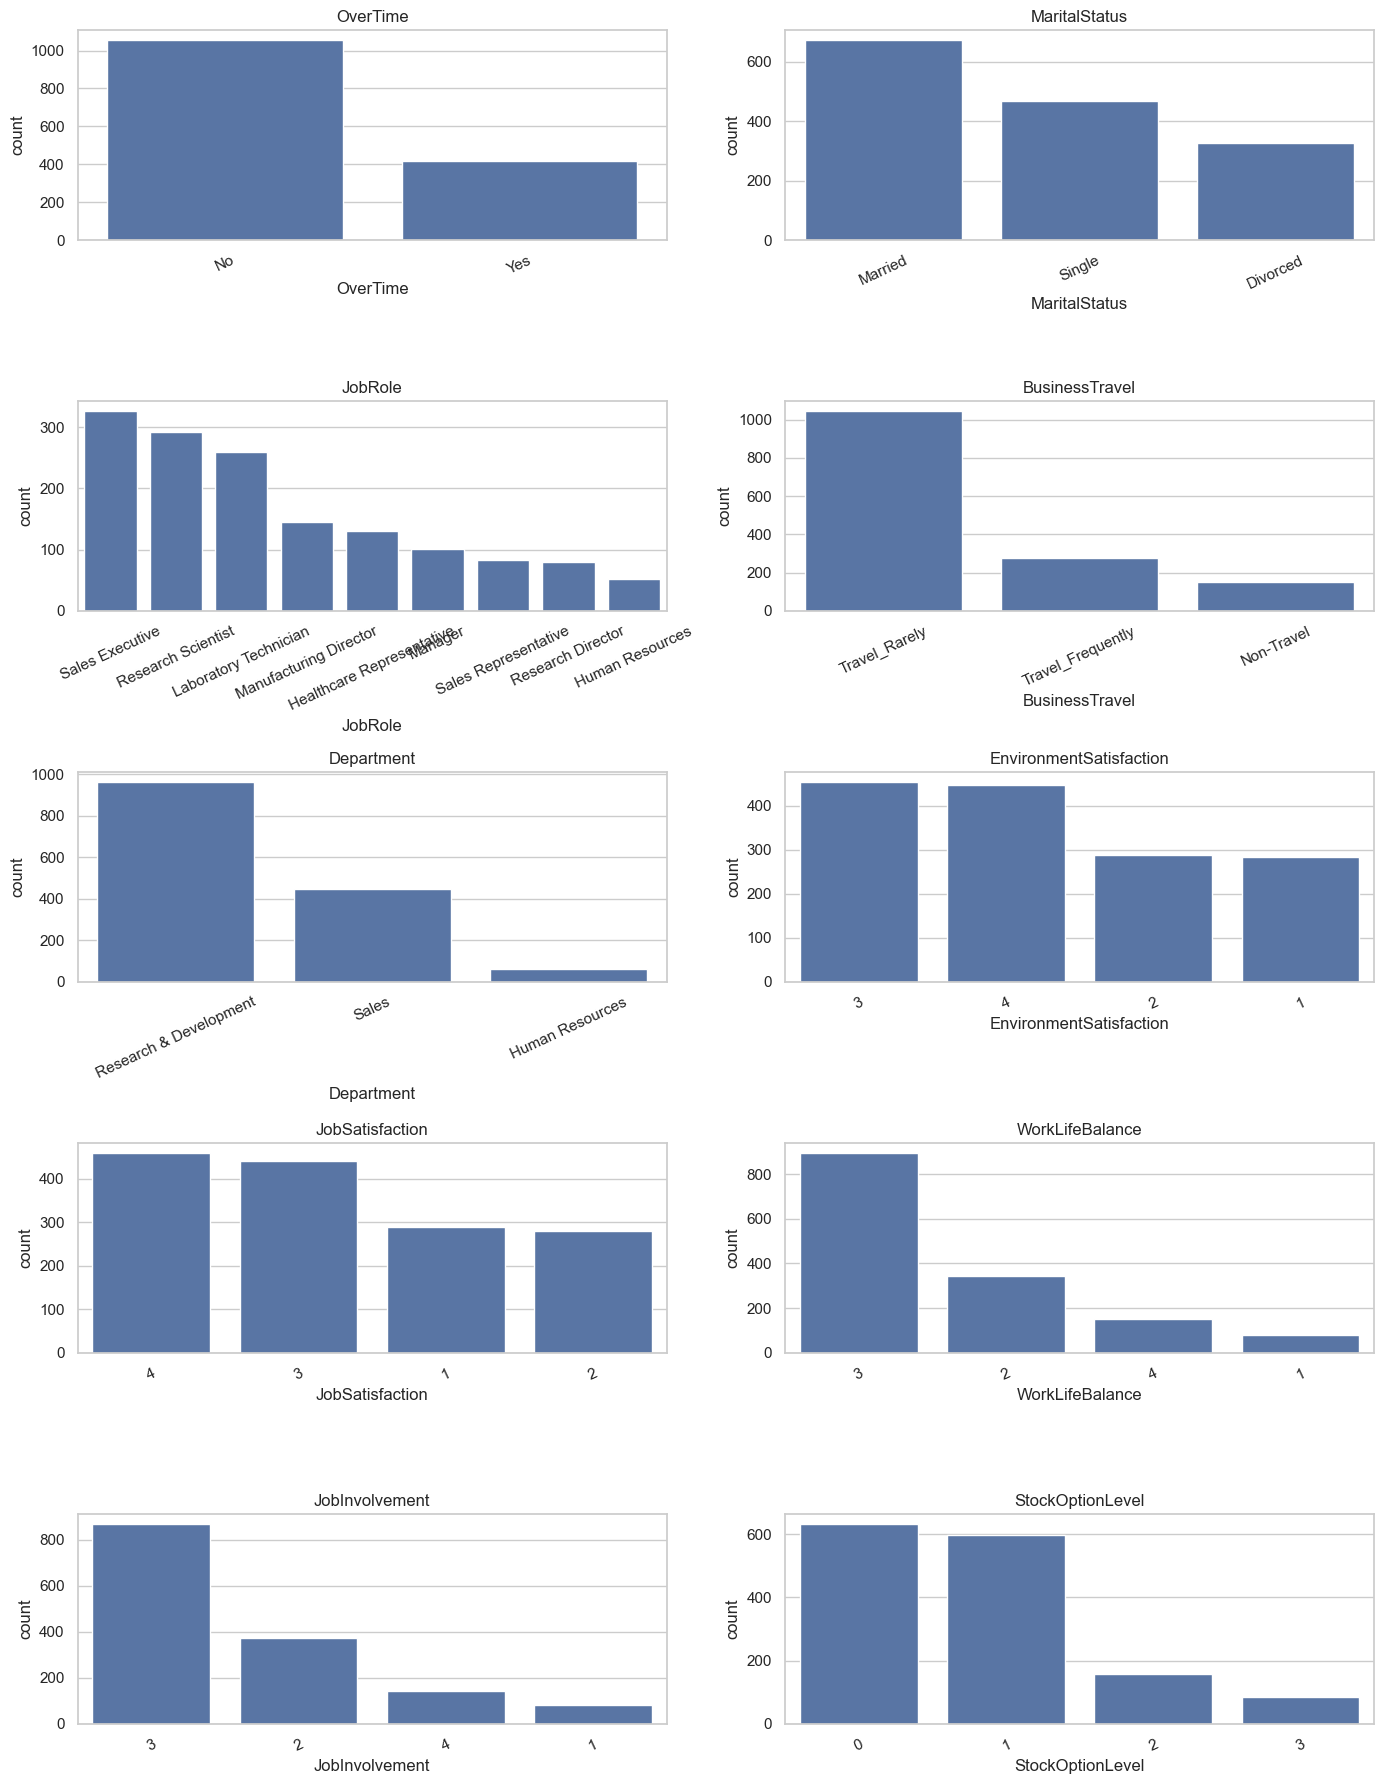

In [31]:
cat_like = [
    "OverTime", "MaritalStatus", "JobRole", "BusinessTravel", 
    "Department", "EnvironmentSatisfaction", "JobSatisfaction", 
    "WorkLifeBalance", "JobInvolvement", "StockOptionLevel"
]

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, c in zip(axes.ravel(), cat_like):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_categorical_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Each feature vs. attrition (bivariate)

### 6.1 Numeric features vs. attrition

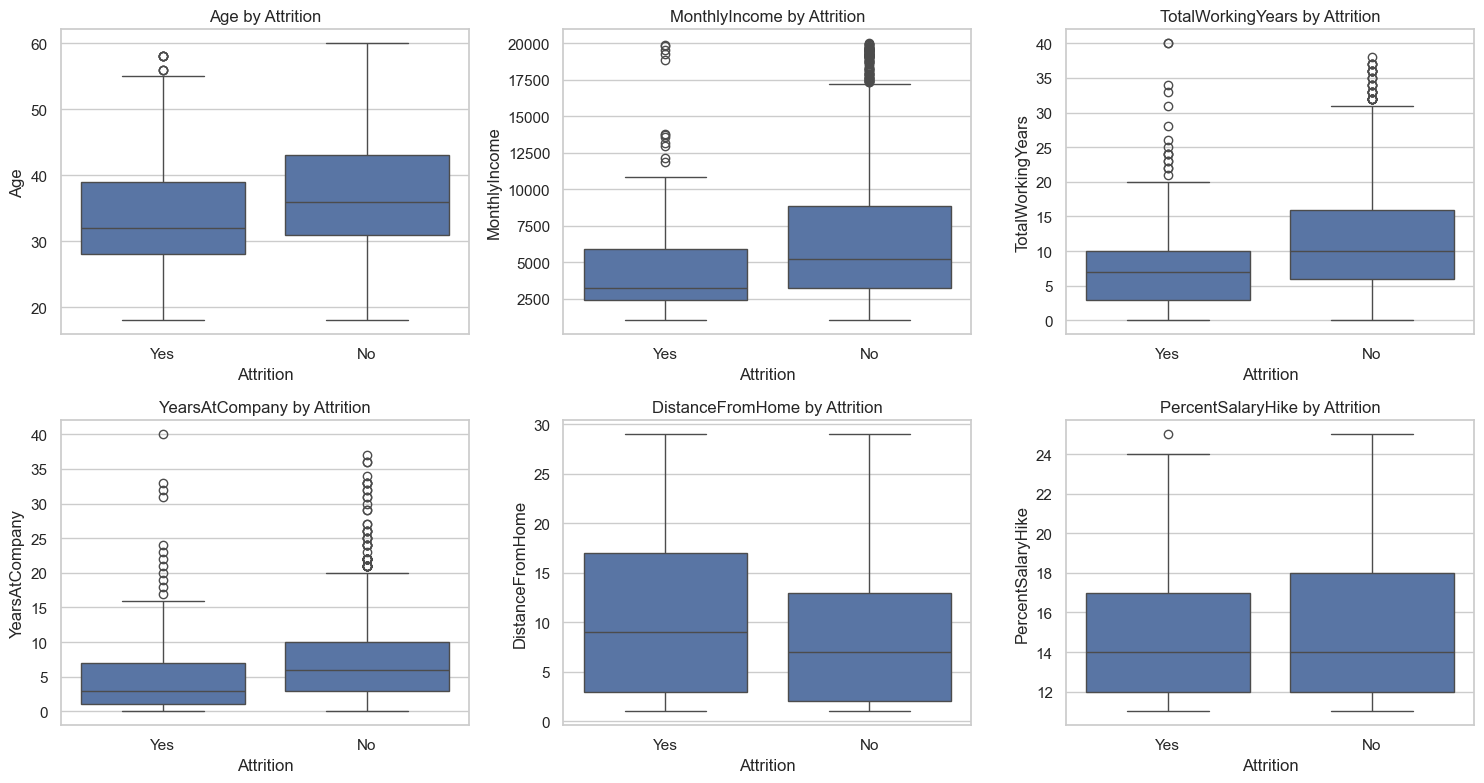

Attrition,stayed (median),attrited (median)
Age,36.00,32.00
MonthlyIncome,"5,204.00","3,202.00"
TotalWorkingYears,10.00,7.00
YearsAtCompany,6.00,3.00
DistanceFromHome,7.00,9.00
PercentSalaryHike,14.00,14.00
YearsInCurrentRole,3.00,2.00
YearsWithCurrManager,3.00,2.00
DailyRate,817.00,699.00


In [32]:
df["Attrition_Num"] = (df[TARGET] == "Yes").astype(int)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), key_num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax)
    ax.set_title(f"{c} by Attrition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_numeric_by_attrition_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

df.groupby(TARGET)[key_num_cols + ["YearsInCurrentRole", "YearsWithCurrManager", "DailyRate"]].median().T.rename(
    columns={"No": "stayed (median)", "Yes": "attrited (median)"}
)

### 6.2 Attrition rate by category

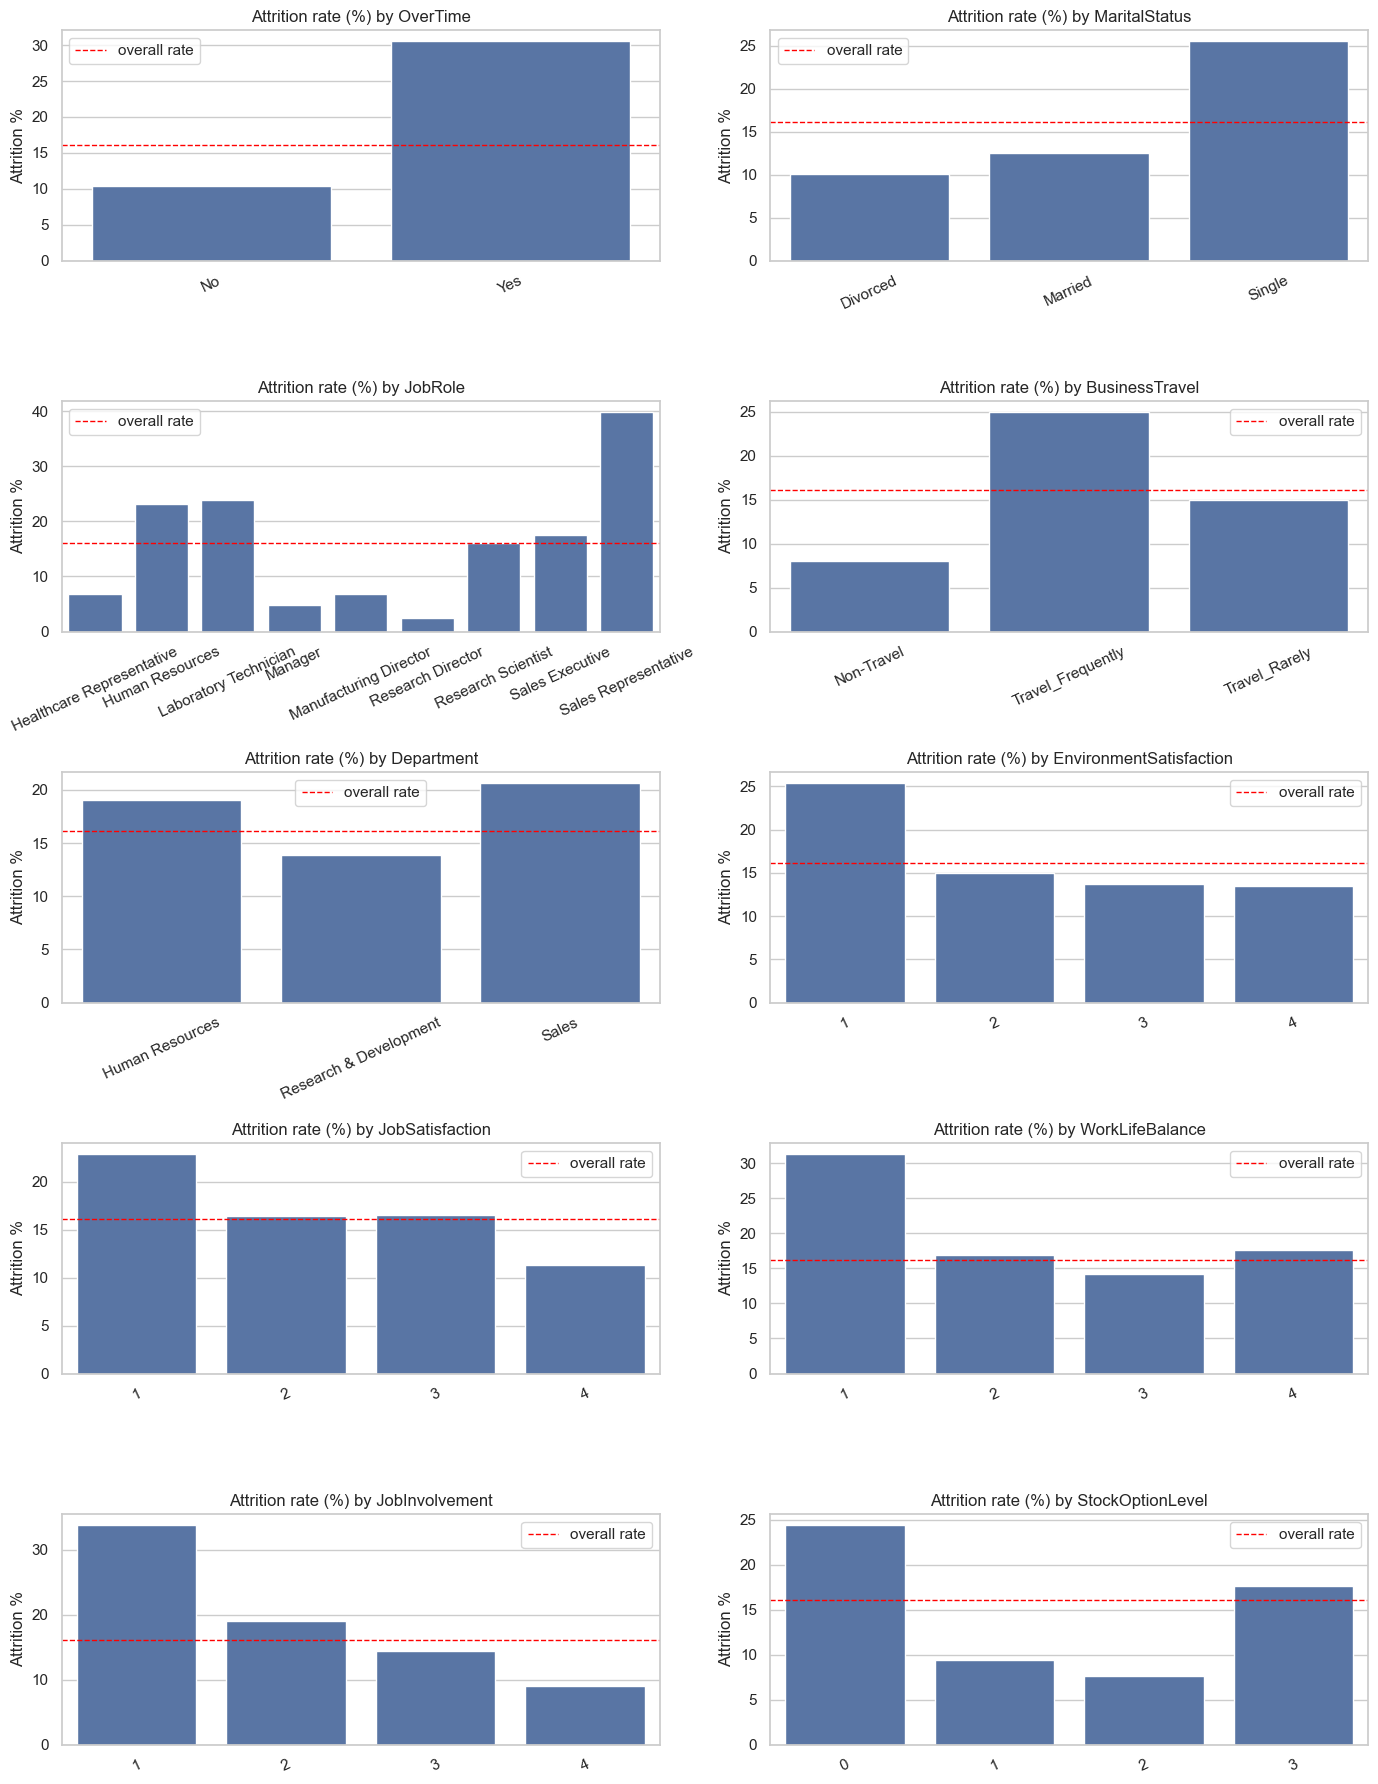

In [33]:
def attrition_rate_by(col, ax, order=None):
    rate = df.groupby(col)["Attrition_Num"].mean().mul(100)
    if order is not None:
        rate = rate.reindex(order)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df["Attrition_Num"].mean() * 100, color="red", ls="--", lw=1, label="overall rate")
    ax.set(title=f"Attrition rate (%) by {col}", xlabel="", ylabel="Attrition %")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, c in zip(axes.ravel(), cat_like):
    attrition_rate_by(c, ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_attrition_rate_by_categories.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.3 Attrition rate by company tenure band

,employees,attrition_rate
YearsAtCompany,,
0-1 yr,215,34.88
2-3 yrs,255,18.43
4-5 yrs,306,13.07
6-10 yrs,448,12.28
11+ yrs,246,8.13


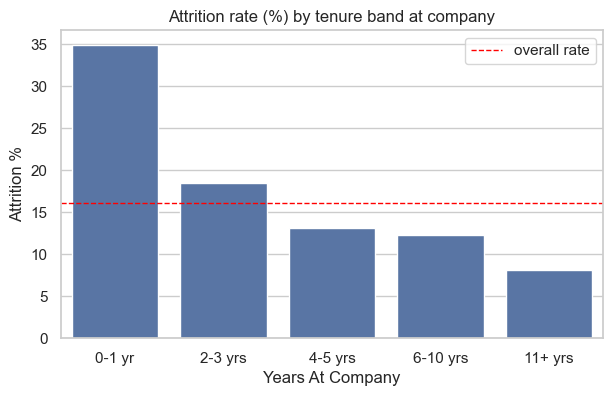

In [35]:
bins = [-1, 1, 3, 5, 10, np.inf]
labels = ["0-1 yr", "2-3 yrs", "4-5 yrs", "6-10 yrs", "11+ yrs"]
tenure_band = pd.cut(df["YearsAtCompany"], bins=bins, labels=labels)

band = (
    df.groupby(tenure_band, observed=True)["Attrition_Num"]
      .agg(employees="count", attrition_rate="mean")
      .assign(attrition_rate=lambda d: d["attrition_rate"] * 100)
)
display(band)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=band.index.astype(str), y=band["attrition_rate"], ax=ax)
ax.axhline(df["Attrition_Num"].mean() * 100, color="red", ls="--", lw=1, label="overall rate")
ax.set(title="Attrition rate (%) by tenure band at company", xlabel="Years At Company", ylabel="Attrition %")
ax.legend()
plt.savefig(FIGURES_DIR / '07_attrition_rate_by_tenure_band.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.4 Overtime and satisfaction/burnout interactions

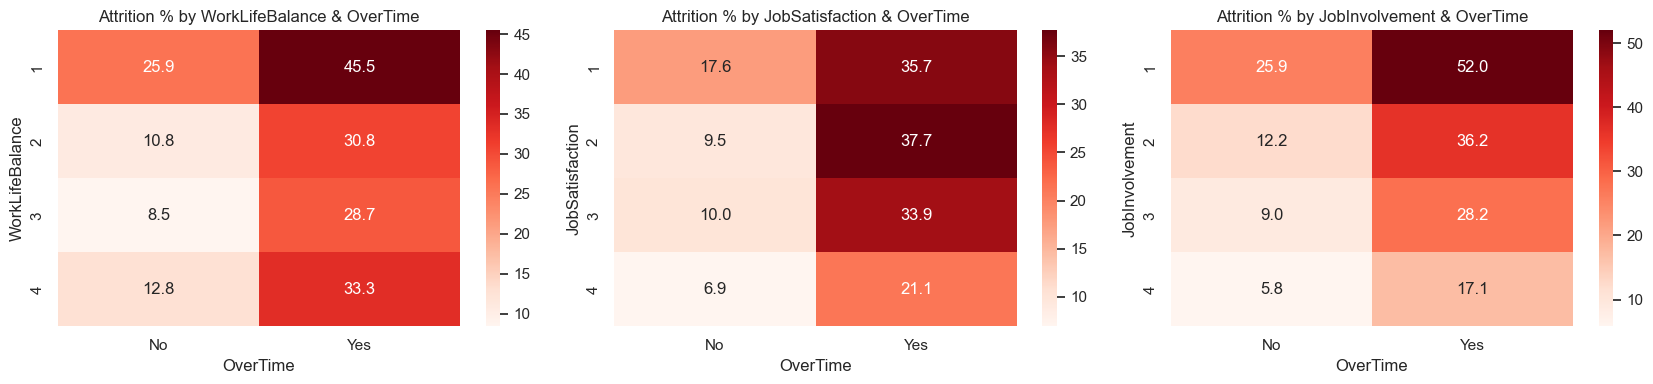

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

piv_wlb = df.pivot_table(index="WorkLifeBalance", columns="OverTime", values="Attrition_Num", aggfunc="mean") * 100
sns.heatmap(piv_wlb, annot=True, fmt=".1f", cmap="Reds", ax=axes[0])
axes[0].set_title("Attrition % by WorkLifeBalance & OverTime")

piv_js = df.pivot_table(index="JobSatisfaction", columns="OverTime", values="Attrition_Num", aggfunc="mean") * 100
sns.heatmap(piv_js, annot=True, fmt=".1f", cmap="Reds", ax=axes[1])
axes[1].set_title("Attrition % by JobSatisfaction & OverTime")

piv_ji = df.pivot_table(index="JobInvolvement", columns="OverTime", values="Attrition_Num", aggfunc="mean") * 100
sns.heatmap(piv_ji, annot=True, fmt=".1f", cmap="Reds", ax=axes[2])
axes[2].set_title("Attrition % by JobInvolvement & OverTime")

plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_overtime_satisfaction_burnout_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Correlation

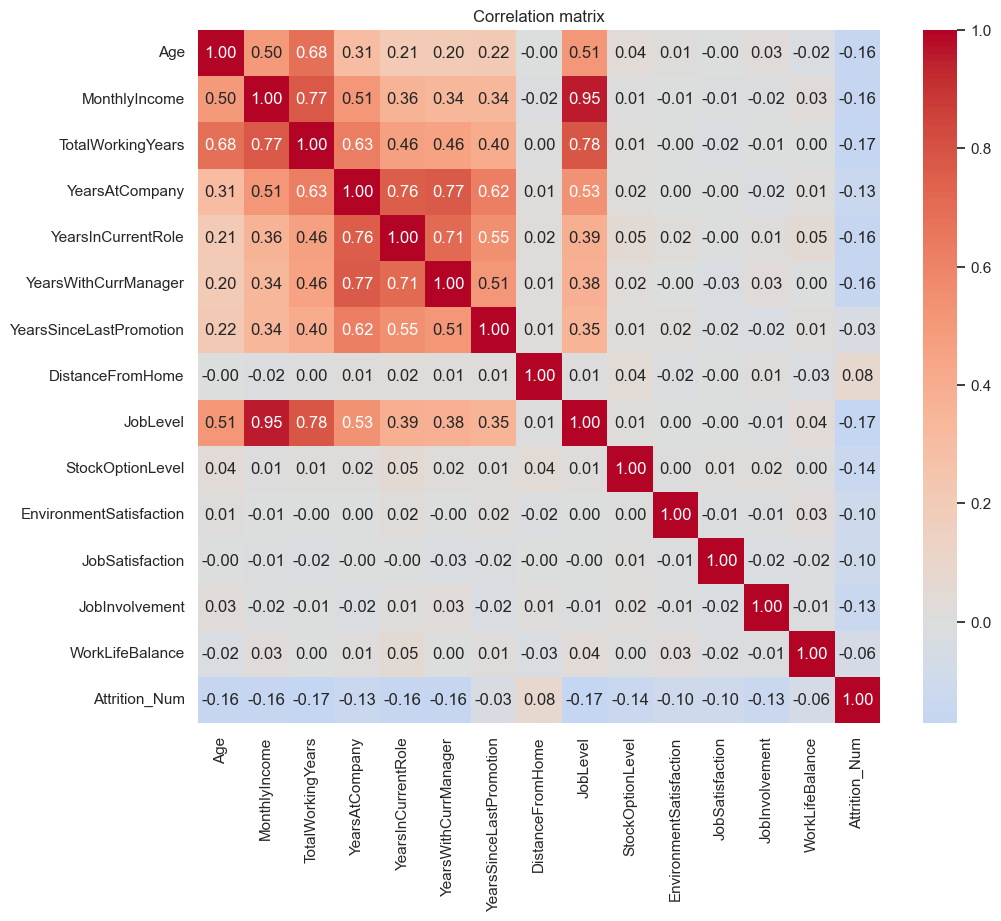

,corr with Attrition
TotalWorkingYears,-0.17
JobLevel,-0.17
YearsInCurrentRole,-0.16
MonthlyIncome,-0.16
Age,-0.16
YearsWithCurrManager,-0.16
StockOptionLevel,-0.14
YearsAtCompany,-0.13
JobInvolvement,-0.13
JobSatisfaction,-0.10


In [37]:
corr_cols = [
    "Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", 
    "YearsInCurrentRole", "YearsWithCurrManager", "YearsSinceLastPromotion",
    "DistanceFromHome", "JobLevel", "StockOptionLevel", 
    "EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", 
    "WorkLifeBalance", "Attrition_Num"
]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.savefig(FIGURES_DIR / '09_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

corr["Attrition_Num"].drop("Attrition_Num").sort_values(key=abs, ascending=False).to_frame("corr with Attrition")

## 8. Key Insights & Recommendations

### 8.1 Key Insights
1. **Overtime & Workload Indicators:**
   - Overtime is among the strongest individual behavioral indicators associated with turnover. Employees logging overtime leave at **30.5%** vs. **10.4%** for non-overtime peers (~$3\times$ higher observed cohort rate). When paired with low work-life balance or low job involvement, subgroup attrition rates exceed **45%–52%** (though sample sizes in these intersectional cells are small, e.g. $n=22$–$25$).
2. **The First-Year Turnover Cliff:**
   - Overall company attrition is **16.1%**, but **34.88%** of employees in their **first year (`0-1 yr`)** leave. Once staff cross 5 years at the firm, attrition stabilizes near **12%**, dropping to **8.1%** past 10 years.
3. **Job Role Disparities:**
   - **Sales Representatives** experience the highest observed attrition rate in the company at **39.8%** ($33/83$), followed by **Laboratory Technicians (23.9%, $62/259$)** and **Human Resources (23.1%, $12/52$)**. In contrast, senior roles like **Research Directors (2.5%, $2/80$)** and **Managers (4.9%, $5/102$)** demonstrate high retention.
4. **Compensation & Equity Associations:**
   - Employees who attrited earn a median of **$3,202/month** vs. **$5,204/month** for retained staff (a **38.5% compensation gap**).
   - Baseline equity participation (**StockOptionLevel 1 or 2**) is associated with lower turnover (**7.6%–9.4%** vs. **24.4%** for Level 0), though Level 3 shows a non-linear uptick to **17.6%** ($15/85$), and equity is heavily confounded by seniority and `JobLevel`.
5. **Demographic & Commute Factors:**
   - **Single employees** leave at **25.5%** (vs. **10.1%** for divorced and **12.5%** for married employees).
   - **Frequent business travelers** leave at **24.9%** (vs. **8.0%** for non-travelers), and longer commute distance shows a positive correlation with turnover.
6. **Data Quality & Non-Informative Columns:**
   - The dataset is 100% complete (0 missing values, 0 duplicates).
   - 4 non-informative columns (`EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`) have zero variance or arbitrary IDs and must be eliminated during preprocessing, leaving 30 predictive features.

---

### 8.2 Actionable Recommendations

#### A. HR & Business Retention Strategy
- **Overtime Monitoring & Fatigue Reviews:** Monitor overtime hours systematically. Trigger proactive HR check-ins for staff logging sustained overtime alongside low survey ratings (`WorkLifeBalance <= 2`).
- **First-Year Onboarding & Mentorship Program:** Establish a structured 30-60-90-365 day onboarding pathway with designated mentors to mitigate the elevated first-year turnover rate.
- **Sales Representative Workflow & Compensation Review:** Review territory distribution, commission structure, and travel demands for Sales Representatives to address the elevated turnover rate in this cohort.
- **Evaluate Equity Grant Policies:** Pilot broader baseline equity participation (Stock Option Level 1) for eligible roles, while evaluating retention impact empirically.
- **Commute & Hybrid Flexibility:** Explore hybrid scheduling or transit subsidies for staff with longer commutes (>10 miles) to alleviate commute friction.

#### B. Data Preprocessing & Feature Engineering Pipeline
- **Drop Non-Informative Columns:** Exclude `EmployeeCount`, `StandardHours`, `Over18`, and `EmployeeNumber` prior to model training.
- **Target Encoding / Mapping:** Map `Attrition` (`{'No': 0, 'Yes': 1}`) and encode categorical features using one-hot encoding for tree models.
- **Engineer High-Impact Features:**
  - `is_first_year`: Binary indicator (`YearsAtCompany <= 1`).
  - `overtime_and_low_wlb`: Interaction indicator (`(OverTime == 'Yes') & (WorkLifeBalance <= 2)`).
  - `income_per_working_year`: `MonthlyIncome / (TotalWorkingYears + 1)` capturing compensation velocity relative to career tenure.
  - `role_to_company_ratio`: `YearsInCurrentRole / (YearsAtCompany + 1)` capturing role progression.
  - `tenure_band`: Segmented bins `['0-1 yr', '2-3 yrs', '4-5 yrs', '6-10 yrs', '11+ yrs']`.
- **Address Class Imbalance & Collinearity:**
  - Employ stratified train/test splits with cost-sensitive weighting (`scale_pos_weight = 5.20`).
  - Favor tree-based ensembles (XGBoost, Random Forest) that naturally handle multicollinear features (`JobLevel` vs. `MonthlyIncome`) and non-linear interactions.
